<a href="https://colab.research.google.com/github/LennardBehmann/Intro-ML/blob/main/Homework_7/HW7_P2b_Sigmoid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 7 — Problem 2.b: Baseline Fully Connected Neural Network

Experiment 2 – Sigmoid Activation: Use the network from Problem 1.a, replacing ReLU activation functions with Sigmoid.


## A. Learning exercises — tensors, flattening, logits, and one update

In [2]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from google.colab import drive

# Connect Google Drive so CIFAR-10 remains available in future sessions.
drive.mount("/content/drive")

transform = transforms.ToTensor()
data_path = "/content/drive/MyDrive/ML_Datasets"

train_dataset = datasets.CIFAR10(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))

# Examine one image
image, label = train_dataset[0]
print("Image shape:", image.shape)
print("Class label:", label)
print("Pixel range:", image.min().item(), image.max().item())

Mounted at /content/drive
Training images: 50000
Image shape: torch.Size([3, 32, 32])
Class label: 6
Pixel range: 0.0 1.0


In [3]:

# Create batches of 64 images
loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Get the first batch
images, labels = next(iter(loader))

print("Before flatten:", images.shape)

# Flatten each image independently
flat_images = images.flatten(start_dim=1)

print("After flatten:", flat_images.shape)


Before flatten: torch.Size([64, 3, 32, 32])
After flatten: torch.Size([64, 3072])


In [4]:

import torch.nn as nn

# First fully connected layer
first_layer = nn.Linear(3072, 256)

# Forward pass
output = first_layer(flat_images)

print("Input shape:", flat_images.shape)
print("Output shape:", output.shape)


Input shape: torch.Size([64, 3072])
Output shape: torch.Size([64, 256])


In [5]:

import torch
import torch.nn as nn


class CIFAR10MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 256),
            nn.Sigmoid(),

            nn.Linear(256, 256),
            nn.Sigmoid(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)

model = CIFAR10MLP()

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)


CIFAR10MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=256, bias=True)
    (2): Sigmoid()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): Sigmoid()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 855050


In [6]:

# Forward pass through our MLP
logits = model(images)

print("Logits shape:", logits.shape)
print("Labels shape:", labels.shape)

# Define our loss function
loss_fn = nn.CrossEntropyLoss()

# Calculate the loss
loss = loss_fn(logits, labels)

print("Initial loss:", loss.item())


Logits shape: torch.Size([64, 10])
Labels shape: torch.Size([64])
Initial loss: 2.33807110786438


In [7]:

# Define the optimizer
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

# 1. Reset old gradients
optimizer.zero_grad()

# 2. Forward pass
logits = model(images)
loss = loss_fn(logits, labels)

print("Loss before update:", loss.item())

# 3. Backpropagation
loss.backward()

# Inspect gradient of first linear layer
print("Gradient norm:",
      model.network[1].weight.grad.norm().item())

# 4. Update weights and biases
optimizer.step()

# 5. Recalculate loss on the same batch
with torch.no_grad():
    new_logits = model(images)
    new_loss = loss_fn(new_logits, labels)

print("Loss after update:", new_loss.item())


Loss before update: 2.33807110786438
Gradient norm: 0.07189066708087921
Loss after update: 2.3286070823669434


## B. Reproducible train/validation split

The professor requires 80/20 of the official CIFAR-10 **training** set: 40,000 for training and 10,000 for validation. The separate official CIFAR-10 **test** set is held out until the final evaluation. We reuse the same tensor transformation on all three subsets.

In [8]:
from torch.utils.data import random_split, DataLoader

BATCH_SIZE = 64
SEED = 42

# Split only the official CIFAR-10 training portion.
split_generator = torch.Generator().manual_seed(SEED)
train_set, val_set = random_split(
    train_dataset,
    [40000, 10000],
    generator=split_generator
)

# Independent RNG for reproducible shuffling of training batches.
shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True,
    generator=shuffle_generator
)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)

# The official 10,000 CIFAR-10 test images are separate from the 80/20 split.
# Reuse the same Google Drive dataset location.
test_dataset = datasets.CIFAR10(
    root=data_path, train=False, download=True, transform=transform
)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Train/validation/test images:", len(train_set), len(val_set), len(test_dataset))
print("Train/validation/test batches:", len(train_loader), len(val_loader), len(test_loader))
assert len(train_set) == 40000 and len(val_set) == 10000
assert len(test_dataset) == 10000

Train/validation/test images: 40000 10000 10000
Train/validation/test batches: 625 157 157


## C. Fresh double-width model and training configuration

**Important:** The demo above uses one training batch before the split. The model below is newly initialized so the demo weights cannot affect validation. The output layer returns raw logits (do not apply Softmax before CrossEntropyLoss).


In [9]:
import random
import numpy as np
from pathlib import Path

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CIFAR10MLP().to(device)  # freshly initialized
loss_fn = nn.CrossEntropyLoss()
LEARNING_RATE = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
NUM_EPOCHS = 80

output_dir = Path("/content/drive/MyDrive/ML_Checkpoints")
output_dir.mkdir(parents=True, exist_ok=True)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Device:", device)
print("Architecture:", model)
print("Trainable parameters:", f"{n_params:,}")
assert n_params == 855050

Device: cuda
Architecture: CIFAR10MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=256, bias=True)
    (2): Sigmoid()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): Sigmoid()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 855,050


## D. Evaluation function

In evaluation mode, use **no gradients** and **no optimizer step**. Weight the mean batch loss by the number of images, so the last, smaller batch receives the correct weight.

In [10]:
def evaluate(model, data_loader, loss_fn, device):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_images, batch_labels in data_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            logits = model(batch_images)
            loss = loss_fn(logits, batch_labels)

            batch_size = batch_labels.size(0)
            loss_sum += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == batch_labels).sum().item()
            total += batch_size

    return loss_sum / total, correct / total

## E. Training, timing, curves, and best validation checkpoint

Each epoch processes all **40,000** training images in **625** SGD steps. `training_seconds` includes the train-batch computation only; `total_experiment_seconds` also includes per-epoch validation. GPU synchronization makes the timing more trustworthy on CUDA.

We use the **lowest validation loss** to select the best epoch. The test set is **never** consulted inside this loop.

In [11]:
import copy
import time

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
epoch_train_seconds = []

best_val_loss = float("inf")
best_val_epoch = None
best_val_accuracy = None
best_state = None
training_seconds = 0.0

# Synchronize only on CUDA to avoid measuring merely enqueued GPU work.
def synchronize_if_cuda():
    if device.type == "cuda":
        torch.cuda.synchronize()

synchronize_if_cuda()
experiment_start = time.perf_counter()

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    synchronize_if_cuda()
    epoch_start = time.perf_counter()

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()
        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)
        loss.backward()
        optimizer.step()

        count = batch_labels.size(0)
        train_loss_sum += loss.item() * count
        train_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        train_count += count

    synchronize_if_cuda()
    epoch_seconds = time.perf_counter() - epoch_start
    epoch_train_seconds.append(epoch_seconds)
    training_seconds += epoch_seconds

    # Online training metrics: computed as weights change during the epoch.
    train_loss = train_loss_sum / train_count
    train_acc = train_correct / train_count

    # Validation metrics: computed AFTER that epoch with fixed weights.
    val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_epoch = epoch
        best_val_accuracy = val_acc
        best_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch:2d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | Val Acc: {val_acc:.2%} | "
        f"Train Time: {epoch_seconds:.1f}s"
    )

synchronize_if_cuda()
total_experiment_seconds = time.perf_counter() - experiment_start

# Save checkpoint and restore best validation-loss weights.
checkpoint_path = output_dir / "p2b_width_best_model.pt"
torch.save(best_state, checkpoint_path)
model.load_state_dict(best_state)

print("\nBest validation-loss epoch:", best_val_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Validation accuracy at best-loss epoch:", f"{best_val_accuracy:.2%}")
print("Training time (excludes validation):", f"{training_seconds:.1f} seconds")
print("Total training + validation runtime:", f"{total_experiment_seconds:.1f} seconds")
print("Best checkpoint saved to:", checkpoint_path)

Epoch  1/80 | Train Loss: 2.3032 | Val Loss: 2.2998 | Train Acc: 10.71% | Val Acc: 10.06% | Train Time: 6.5s
Epoch  2/80 | Train Loss: 2.2984 | Val Loss: 2.2938 | Train Acc: 11.71% | Val Acc: 17.06% | Train Time: 5.3s
Epoch  3/80 | Train Loss: 2.2918 | Val Loss: 2.2875 | Train Acc: 13.39% | Val Acc: 12.72% | Train Time: 6.5s
Epoch  4/80 | Train Loss: 2.2815 | Val Loss: 2.2743 | Train Acc: 15.15% | Val Acc: 15.96% | Train Time: 5.4s
Epoch  5/80 | Train Loss: 2.2632 | Val Loss: 2.2487 | Train Acc: 17.08% | Val Acc: 17.07% | Train Time: 6.5s
Epoch  6/80 | Train Loss: 2.2311 | Val Loss: 2.2091 | Train Acc: 18.41% | Val Acc: 19.62% | Train Time: 5.3s
Epoch  7/80 | Train Loss: 2.1854 | Val Loss: 2.1637 | Train Acc: 19.71% | Val Acc: 20.48% | Train Time: 6.4s
Epoch  8/80 | Train Loss: 2.1396 | Val Loss: 2.1208 | Train Acc: 20.55% | Val Acc: 21.40% | Train Time: 5.3s
Epoch  9/80 | Train Loss: 2.1063 | Val Loss: 2.0922 | Train Acc: 21.59% | Val Acc: 21.68% | Train Time: 6.4s
Epoch 10/80 | Train

## F. Final evaluation (once, after selecting the checkpoint)

Evaluate **the same selected checkpoint** on training, validation and test images. Unlike the online training metrics in the curves, these three metrics all use fixed weights and are directly comparable. The test result should be reported as **test / evaluation accuracy**, not confused with validation accuracy.

In [12]:
# Checkpoint is already loaded into model above.
selected_train_loss, selected_train_acc = evaluate(model, train_loader, loss_fn, device)
selected_val_loss, selected_val_acc = evaluate(model, val_loader, loss_fn, device)
selected_test_loss, selected_test_acc = evaluate(model, test_loader, loss_fn, device)

print(f"Selected checkpoint: epoch {best_val_epoch} (of max {NUM_EPOCHS})")
print(f"Training Loss:     {selected_train_loss:.4f}")
print(f"Training Accuracy: {selected_train_acc:.2%}")
print(f"Validation Loss:   {selected_val_loss:.4f}")
print(f"Validation Accuracy: {selected_val_acc:.2%}")
print(f"Test Loss:         {selected_test_loss:.4f}")
print(f"Test Accuracy:     {selected_test_acc:.2%}")
print(f"Parameters:        {n_params:,}")
print(f"Training Time:     {training_seconds:.1f}s (training only)")
print(f"Train-Test Gap:    {(selected_train_acc - selected_test_acc)*100:.2f} percentage points")

Selected checkpoint: epoch 80 (of max 80)
Training Loss:     1.6477
Training Accuracy: 40.97%
Validation Loss:   1.6661
Validation Accuracy: 40.13%
Test Loss:         1.6554
Test Accuracy:     40.86%
Parameters:        855,050
Training Time:     447.7s (training only)
Train-Test Gap:    0.11 percentage points


## G. Training curves (required for report)

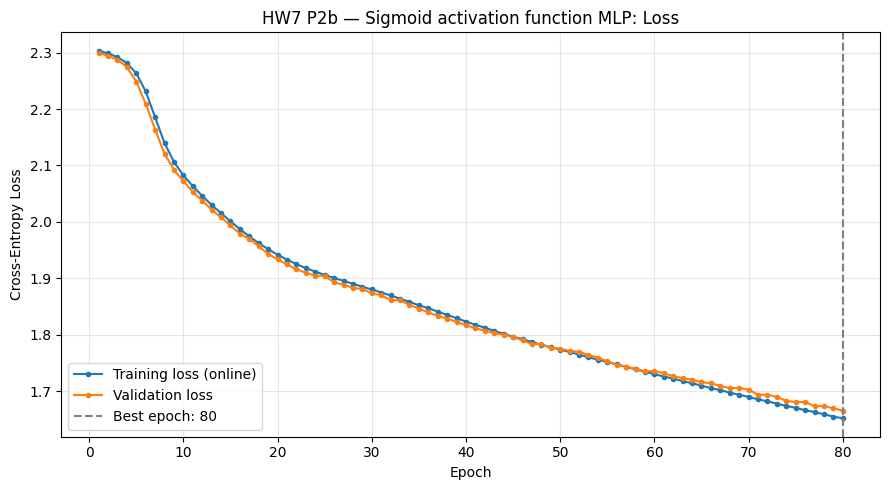

In [13]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, marker="o", markersize=3, label="Training loss (online)")
plt.plot(epochs, val_losses, marker="o", markersize=3, label="Validation loss")
plt.axvline(best_val_epoch, color="gray", linestyle="--", label=f"Best epoch: {best_val_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("HW7 P2b — Sigmoid activation function MLP: Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

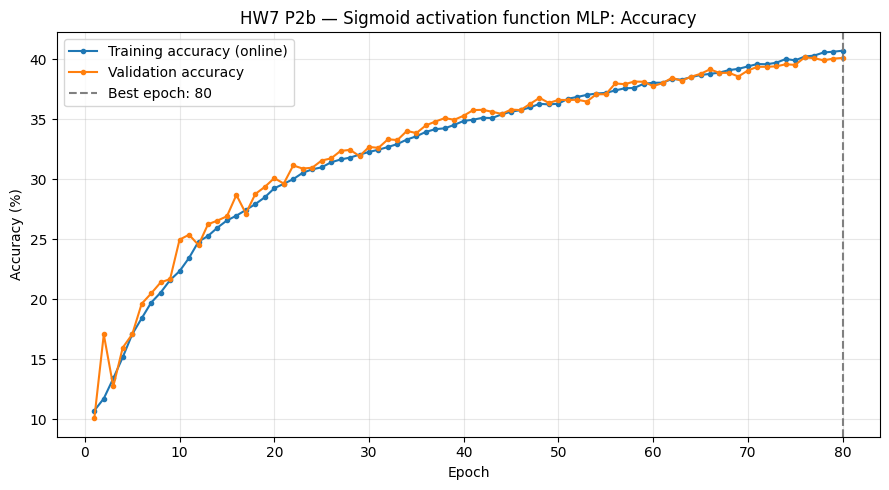

In [14]:
plt.figure(figsize=(9, 5))
plt.plot(epochs, [100*x for x in train_accuracies], marker="o", markersize=3, label="Training accuracy (online)")
plt.plot(epochs, [100*x for x in val_accuracies], marker="o", markersize=3, label="Validation accuracy")
plt.axvline(best_val_epoch, color="gray", linestyle="--", label=f"Best epoch: {best_val_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("HW7 P2b — Sigmoid activation function MLP: Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()